# 07 · Modèles et suivi des expériences (MLflow)

**Question** : un modèle qui combine les 19 variables fait-il nettement mieux que le bon sens (précision@10 de 17,3 %) ?

**Règle de décision, fixée avant ce notebook** : un modèle est retenu si, sur la validation, (1) sa précision@10 dépasse la baseline d'au moins 3 points, (2) l'intervalle de confiance à 95 % du gain ne contient pas zéro, (3) il ne fait moins bien qu'elle aucun mois.

### MLflow en une phrase

MLflow est le **cahier de laboratoire** du data scientist. Chaque essai (un **run**) y est enregistré automatiquement : le modèle, ses réglages (**paramètres**), ses scores (**métriques**) et le modèle lui-même (**artefact**). Dans trois semaines, on saura exactement quel essai a donné quel score, et on pourra recharger le modèle correspondant.


### Les deux familles de modèles

| Modèle | Principe en une phrase | Forces | Limites |
|---|---|---|---|
| Régression logistique | Une somme pondérée des variables, transformée en probabilité | Simple, rapide, chaque poids s'interprète | Ne capte pas les interactions (« beaucoup de pannes ET usage en baisse ») |
| Gradient boosting (HistGradientBoosting) | Des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents | Capte les interactions et les effets de seuil, gère les manquants | Plus difficile à expliquer, risque de sur-apprendre |

Chacun est testé **avec et sans le site** (notebook 05 : le site peut aider ou être simplement mémorisé).

In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

from evrel.data.load import get_data_dir, load_config
from evrel.models.baselines import baseline_scores
from evrel.models.compare import monthly_precision
from evrel.models.evaluate import top_k_rows
from evrel.models.train import BASELINE, feature_columns, make_model, run_experiment, setup_mlflow
from evrel.viz import INK_2, NEUTRAL, PALETTE, set_style

set_style()
setup_mlflow()
feats = pd.read_parquet(get_data_dir() / "processed" / "features.parquet")
train = feats[feats["split"] == "train"].copy()
valid = feats[feats["split"] == "valid"].copy()                   # le test reste fermé
valid[BASELINE] = baseline_scores(valid)[BASELINE]
print(f"Entraînement : {len(train):,} lignes, {train['y'].mean():.1%} d'épisodes")
print(f"Validation   : {len(valid):,} lignes, {valid['y'].mean():.1%} d'épisodes")
print(f"MLflow       : {mlflow.get_tracking_uri()}")

Entraînement : 26,860 lignes, 7.0% d'épisodes
Validation   : 9,760 lignes, 6.2% d'épisodes
MLflow       : sqlite:///C:/dev/ev-reliability-data/mlflow/mlflow.db


## 1. Les essais

Chaque ligne ci-dessous est un **run** MLflow. Pour le gradient boosting, on essaie quelques réglages raisonnables, pas une recherche exhaustive : avec une seule période de validation, multiplier les essais finit par trouver un réglage chanceux.

In [3]:
EXPERIMENTS = [
    ("Logistique",                 "logreg", False, {"C": 1.0}),
    ("Logistique + site",          "logreg", True,  {"C": 1.0}),
    ("Boosting prudent",           "hgb",    False, {"learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 15, "min_samples_leaf": 100}),
    ("Boosting standard",          "hgb",    False, {"learning_rate": 0.1,  "max_iter": 200, "max_leaf_nodes": 31, "min_samples_leaf": 20}),
    ("Boosting prudent + site",    "hgb",    True,  {"learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 15, "min_samples_leaf": 100}),
]

results, scores = {}, {}
for name, kind, use_site, params in EXPERIMENTS:
    metrics, s = run_experiment(train, valid, kind, use_site, run_name=name, **params)
    results[name], scores[name] = metrics, s
    print(f"{name:<26} précision@10 = {metrics['précision@10']:.1%}   gain = {metrics['gain']*100:+.1f} pts")

table = pd.DataFrame(results).T
cols = ["précision@10", "rappel@10", "précision@5", "PR-AUC", "AUC", "brier", "gain", "ic_bas", "ic_haut", "retenu"]
table[cols]

2026/10/11 22:39:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\orose\OneDrive\Documents\omr-portfolio\projects\ml-mlops\ev-charging-reliability\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as double

Logistique                 précision@10 = 18.2%   gain = +0.8 pts


2026/10/11 22:39:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\orose\OneDrive\Documents\omr-portfolio\projects\ml-mlops\ev-charging-reliability\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as double

Logistique + site          précision@10 = 19.0%   gain = +1.7 pts


2026/10/11 22:39:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\orose\OneDrive\Documents\omr-portfolio\projects\ml-mlops\ev-charging-reliability\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as double

...

2026/10/11 22:39:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\orose\OneDrive\Documents\omr-portfolio\projects\ml-mlops\ev-charging-reliability\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as double

Boosting standard          précision@10 = 19.2%   gain = +1.8 pts


2026/10/11 22:39:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\orose\OneDrive\Documents\omr-portfolio\projects\ml-mlops\ev-charging-reliability\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as double

Boosting prudent + site    précision@10 = 20.2%   gain = +2.9 pts


,précision@10,rappel@10,précision@5,PR-AUC,AUC,brier,gain,ic_bas,ic_haut,retenu
Logistique,0.181667,0.362126,0.253333,0.249092,0.727956,0.052521,0.008333,-0.007500,0.025000,0.0
Logistique + site,0.190000,0.378738,0.263333,0.251197,0.754655,0.052410,0.016667,0.000000,0.033333,0.0
Boosting prudent,0.197500,0.393688,0.258333,0.268944,0.768409,0.051407,0.024167,0.004167,0.043333,0.0
Boosting standard,0.191667,0.382060,0.251667,0.263539,0.760299,0.051472,0.018333,-0.002500,0.039187,0.0
Boosting prudent + site,0.202500,0.403654,0.266667,0.275380,0.769042,0.051241,0.029167,0.009167,0.049167,0.0


## 2. Comparaison avec la baseline

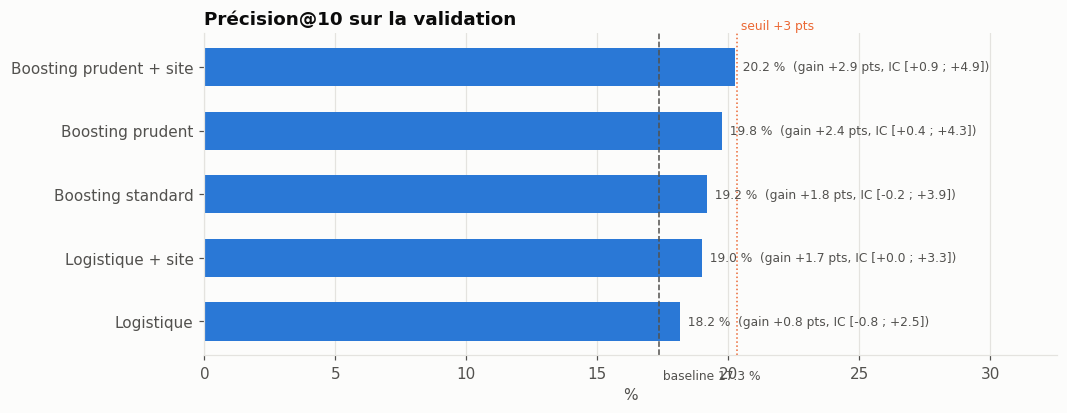

In [4]:
base_prec = (top_k_rows(valid, BASELINE, 10)["y"].mean())
order = table["précision@10"].sort_values().index

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(order, table.loc[order, "précision@10"] * 100, color=PALETTE[0], height=0.6)
for y, name in enumerate(order):
    lo, hi = table.loc[name, "ic_bas"] * 100, table.loc[name, "ic_haut"] * 100
    ax.text(table.loc[name, "précision@10"] * 100, y,
            f"  {table.loc[name, 'précision@10']*100:.1f} %  (gain {table.loc[name, 'gain']*100:+.1f} pts, IC [{lo:+.1f} ; {hi:+.1f}])",
            va="center", fontsize=8, color=INK_2)
ax.axvline(base_prec * 100, color=INK_2, lw=1, ls="--")
ax.axvline(base_prec * 100 + 3, color=PALETTE[1], lw=1, ls=":")
ax.text(base_prec * 100, -0.9, f" baseline {base_prec*100:.1f} %", fontsize=8, color=INK_2)
ax.text(base_prec * 100 + 3, len(order) - 0.4, " seuil +3 pts", fontsize=8, color=PALETTE[1])
ax.set_title("Précision@10 sur la validation")
ax.set_xlabel("%")
ax.set_xlim(0, max(table["précision@10"].max() * 100, base_prec * 100 + 3) * 1.6)
ax.grid(axis="y", visible=False)
plt.show()

**Constat** : les cinq modèles battent la baseline (17,3 %). Le meilleur est le boosting prudent avec le site : 20,25 % de précision@10, soit +2,92 points, avec un intervalle de confiance à 95 % de [+0,9 ; +4,9]. Le classement suit la logique attendue : le boosting fait mieux que la logistique (18,2 % à 19,0 %), la version prudente mieux que la standard, et le site ajoute environ un point. La qualité globale du classement est presque doublée : PR-AUC de 0,275 contre 0,149 pour la baseline.

## 3. Le meilleur modèle, mois par mois

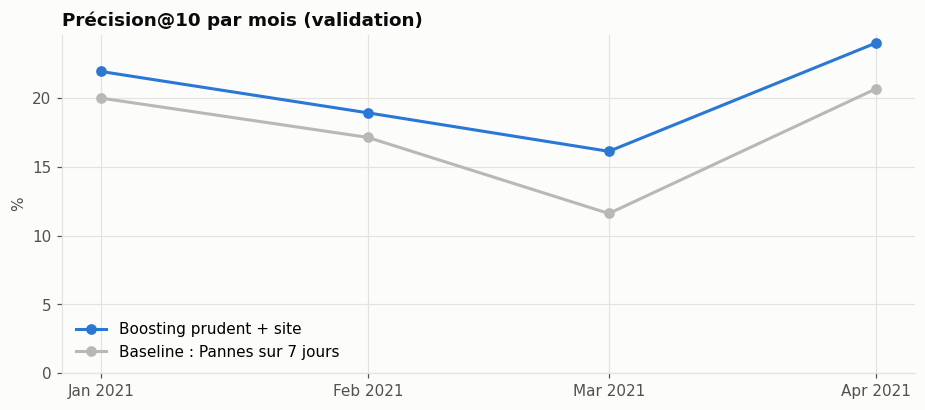

Décision pour « Boosting prudent + site » :


,respectée
c1_gain_suffisant,False
c2_gain_significatif,True
c3_aucun_mois_perdant,True
retenu,False


In [5]:
best = table["précision@10"].idxmax()
valid["score"] = scores[best]
months = monthly_precision(valid, ["score", BASELINE]) * 100

fig, ax = plt.subplots()
ax.plot(months.index.to_timestamp(), months["score"], marker="o", color=PALETTE[0], label=best)
ax.plot(months.index.to_timestamp(), months[BASELINE], marker="o", color=NEUTRAL, label=f"Baseline : {BASELINE}")
ax.set_title("Précision@10 par mois (validation)")
ax.set_ylabel("%")
ax.set_ylim(bottom=0)
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()
print(f"Décision pour « {best} » :")
table.loc[best, ["c1_gain_suffisant", "c2_gain_significatif", "c3_aucun_mois_perdant", "retenu"]].astype(bool).to_frame("respectée")

**Constat** : le meilleur modèle fait mieux que la baseline chaque mois : 22 contre 20 % en janvier, 19 contre 17 % en février, 16 contre 11,6 % en mars, 24 contre 20,6 % en avril. Son avance est la plus nette en mars, le mois le plus difficile.

**Règle de décision** : condition 1 (au moins +3 points) **non remplie**, avec un gain de 2,92 points, soit 35 inspections utiles de plus que la baseline sur 1 200 au lieu des 36 requises. Condition 2 (gain significatif) remplie. Condition 3 (aucun mois perdant) remplie. Le modèle n'est donc **pas retenu** comme remplaçant de la baseline.

## 4. Les probabilités sont-elles fiables ? (calibration)

Si le modèle annonce « 20 % de risque » pour un groupe de bornes, environ 20 % d'entre elles devraient avoir un épisode. La courbe compare risque annoncé et fréquence observée : un modèle bien calibré suit la diagonale.

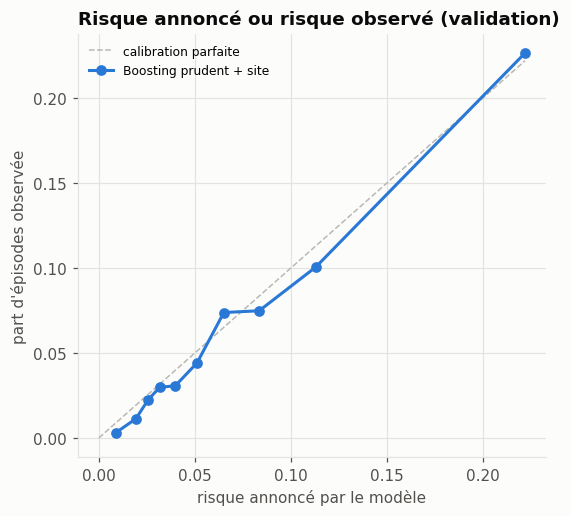

Risque moyen annoncé : 6.6%   Taux réel : 6.2%


In [6]:
prob_true, prob_pred = calibration_curve(valid["y"], valid["score"], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, prob_pred.max()], [0, prob_pred.max()], color=NEUTRAL, ls="--", lw=1, label="calibration parfaite")
ax.plot(prob_pred, prob_true, marker="o", color=PALETTE[0], label=best)
ax.set_title("Risque annoncé ou risque observé (validation)")
ax.set_xlabel("risque annoncé par le modèle")
ax.set_ylabel("part d'épisodes observée")
ax.legend(fontsize=8)
plt.show()
print(f"Risque moyen annoncé : {valid['score'].mean():.1%}   Taux réel : {valid['y'].mean():.1%}")

**Constat** : le modèle annonce un risque moyen de 6,6 % pour 6,2 % d'épisodes observés, et la courbe suit presque parfaitement la diagonale (score de Brier 0,0512). Ses probabilités sont fiables : quand il annonce 20 % de risque, un épisode survient environ 2 fois sur 10.


## 5. Qu'est-ce qui pèse dans les décisions du modèle ?

**Importance par permutation** : on mélange une variable au hasard sur la validation et on mesure combien la qualité du classement (PR-AUC) baisse. Plus la baisse est forte, plus le modèle s'appuie sur cette variable.

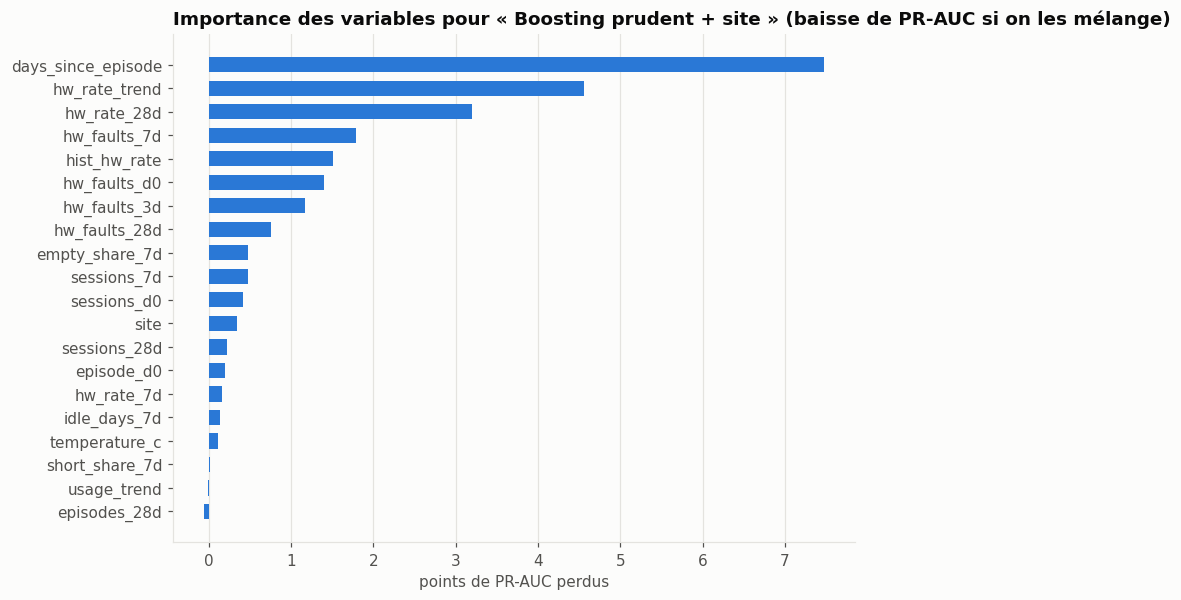

In [7]:
best_kind, best_site, best_params = next((k, s, p) for n, k, s, p in EXPERIMENTS if n == best)
cols = feature_columns(best_site)
model = make_model(best_kind, best_site, **best_params).fit(train[cols], train["y"])
imp = permutation_importance(model, valid[cols], valid["y"], scoring="average_precision",
                             n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=cols).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values * 100, color=PALETTE[0], height=0.65)
ax.set_title(f"Importance des variables pour « {best} » (baisse de PR-AUC si on les mélange)")
ax.set_xlabel("points de PR-AUC perdus")
ax.grid(axis="y", visible=False)
plt.show()

**Constat** : le modèle s'appuie d'abord sur les jours depuis le dernier épisode, la tendance du taux de pannes (7 jours comparés à 28) et le taux de pannes sur 28 jours. Le site n'arrive qu'en 12e position, la météo et les signaux faibles pèsent très peu.


## 6. La liste du modèle est-elle plus variée que celle du bon sens ?

In [8]:
def diversity(col):
    top = top_k_rows(valid, col, 10)
    freq = top["post_id"].value_counts()
    nouveaute = 1 - top["episode_d0"].mean()          # part de la liste qui n'était pas déjà en épisode
    return {"bornes différentes": freq.size,
            "part des 10 plus fréquentes %": round(freq.head(10).sum() / freq.sum() * 100, 1),
            "bornes pas déjà en épisode %": round(nouveaute * 100, 1)}

pd.DataFrame({best: diversity("score"), BASELINE: diversity(BASELINE)}).T

,bornes différentes,part des 10 plus fréquentes %,bornes pas déjà en épisode %
Boosting prudent + site,56.0,52.4,67.5
Pannes sur 7 jours,45.0,61.8,78.5


**Constat** : la liste du modèle est plus variée que celle de la baseline : 56 bornes différentes en 120 soirs contre 45, et 52,4 % des places occupées par les 10 bornes les plus fréquentes contre 61,8 %. En revanche, 32,5 % de sa liste est déjà en épisode le jour même, contre 21,5 % pour la baseline : le modèle s'appuie davantage sur la persistance.


## Ce qu'on retient

- **Tous les modèles battent le bon sens**, le boosting prudent avec le site en tête : 20,25 % de précision@10 contre 17,3 %.
- **Il manque le seuil fixé à l'avance d'une seule inspection utile sur 1 200** : la règle est respectée, le modèle n'est pas retenu comme champion.
- **Il est pourtant meilleur sur tout le reste** : chaque mois, en qualité de classement (PR-AUC presque doublée), en calibration et en diversité.
- **Il a appris une logique métier** : épisode récent, tendance du taux de pannes, taux habituel.
- **Champion / challenger** : la baseline reste en service, le modèle est observé sur des données nouvelles..

